# RANKL M199K vs Wild-Type

MSBD 502, Computational Structural Biology — RANKL M199K / Osteopetrosis Final Project.

This notebook combines three methods into one pipeline, all run on two structures (`RANKL_WT.pdb` and `RANKL_M199K.pdb`, PDB 3URF chain A, residues 162-317):

**A. Structural comparison** — py3Dmol visualization + a distance table around residue 199 applied to the mutation sute instead of a ligand. ( Reference MSBD 502 Lecture 3 (protein-ligand visualization).

**B. PyRosetta** — adapted/ refernces  directly from MSBD 502 Lecture 6 (Rosetta docking and mutational). We mutate residue 199 from methionine to lysine on the wild-type pose, relax both wild-type and mutant the same way, and compute ΔΔG_fold. This is the computational version of what Qiu et al. (2021, *J Cell Physiol* ), measured experimentally with differential scanning fluorimetry: whether M199K destabilizes RANKL.

**C. Molecular dynamics** — OpenMM with the AMBER.ipynb force field (Reference MSBD 502 Class homework Amber Making it Rain. Please note running  on both structures ,RMSD/RMSF comparison,  to observe where the mutant gets unstable over time.

Summary Computational tools Pipeline : PyMOL/py3Dmol for geometry, PyRosetta for physics-based scoring, OpenMM for dynamics.

**Before running:** upload RANKL_WT.pdb and RANKL_M199K.pdb to the Colab folder.

## Setup

Everything installs via pip, no conda and no runtime restart required.

In [ ]:
!pip install -q openmm pdbfixer MDAnalysis py3Dmol biopython matplotlib pandas numpy
print("Core packages installed.")

Core packages installed.


In [ ]:
!pip install -q pyrosetta-installer
import pyrosetta_installer
pyrosetta_installer.install_pyrosetta(skip_if_installed=True)
print("PyRosetta installed.")

PyRosetta install detected, doing nothing...
PyRosetta installed.


In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import py3Dmol
from Bio.PDB import PDBParser, NeighborSearch

import pyrosetta
from pyrosetta import pose_from_pdb, get_fa_scorefxn
from pyrosetta.toolbox import mutate_residue
from pyrosetta.rosetta.protocols.relax import FastRelax

# init flags
pyrosetta.init("-ex1 -ex2 -use_input_sc -ignore_unrecognized_res -ignore_zero_occupancy false -mute all")

WT_PATH = "RANKL_WT.pdb"
MUT_PATH = "RANKL_M199K.pdb"
OUT_DIR = "rankl_pipeline_output"
os.makedirs(OUT_DIR, exist_ok=True)

for p in (WT_PATH, MUT_PATH):
    assert os.path.exists(p), f"Can't find {p} -- upload it to the Colab file browser first."
print("Found both structures. Ready.")

┌───────────────────────────────────────────────────────────────────────────────┐
│                                  PyRosetta-4                                  │
│               Created in JHU by Sergey Lyskov and PyRosetta Team              │
│               (C) Copyright Rosetta Commons Member Institutions               │
│                                                                               │
│ NOTE: USE OF PyRosetta FOR COMMERCIAL PURPOSES REQUIRES PURCHASE OF A LICENSE │
│          See LICENSE.PyRosetta.md or email license@uw.edu for details         │
└───────────────────────────────────────────────────────────────────────────────┘
PyRosetta-4 2026 [Rosetta PyRosetta4.Release.python313.ubuntu 2026.39+release.49e05e797ca4383c6038f090e5db6c2593cb4963 2026-09-21T09:15:10] retrieved from: http://www.pyrosetta.org
Found both structures. Ready.


## A. Structural comparison (py3Dmol + distance table)

Binding-site analysis, applied to residue 199 instead of a ligand: find residues near the mutation site, then compare the distances in wild-type vs. mutant.

In [ ]:
parser = PDBParser(QUIET=True)
struct_wt = parser.get_structure("WT", WT_PATH)
struct_mut = parser.get_structure("MUT", MUT_PATH)
model_wt = struct_wt[0]
model_mut = struct_mut[0]

chain_wt = next(iter(model_wt))
chain_mut = next(iter(model_mut))

res199_wt = chain_wt[199]
print("Wild-type residue 199:", res199_wt.get_resname())
print("Mutant residue 199:", chain_mut[199].get_resname())

Wild-type residue 199: MET
Mutant residue 199: LYS


In [ ]:
# find residues near 199 in the wild-type structure
all_atoms_wt = list(model_wt.get_atoms())
ns_wt = NeighborSearch(all_atoms_wt)

site_atom = res199_wt["CA"]
nearby = ns_wt.search(site_atom.coord, 8.0)
neighbor_resis = sorted(set(a.get_parent().id[1] for a in nearby
                             if a.get_parent().id[1] != 199 and a.get_parent().id[0] == " "))
print(f"Residues within 8 A of residue 199 (CA-CA): {neighbor_resis}")

rows = []
for resi in neighbor_resis:
    try:
        d_wt = chain_wt[199]["CA"] - chain_wt[resi]["CA"]
        d_mut = chain_mut[199]["CA"] - chain_mut[resi]["CA"]
        rows.append({"residue": resi, "wt_distance_A": round(d_wt, 2), "mutant_distance_A": round(d_mut, 2),
                     "delta_A": round(d_mut - d_wt, 2)})
    except KeyError:
        continue

df_distances = pd.DataFrame(rows)
df_distances.to_csv(f"{OUT_DIR}/residue199_distance_table.csv", index=False)
df_distances

Residues within 8 A of residue 199 (CA-CA): [164, 165, 166, 196, 197, 198, 200, 201, 206, 207, 208, 209, 210, 214]


,residue,wt_distance_A,mutant_distance_A,delta_A
0,164,6.16,6.18,0.02
1,165,6.76,6.76,0.00
2,166,7.10,7.08,-0.01
3,196,6.64,6.60,-0.05
4,197,5.46,5.43,-0.04
5,198,3.76,3.74,-0.02
6,200,3.75,3.72,-0.03
7,201,6.83,6.80,-0.03
8,206,7.12,7.12,0.01
9,207,5.72,5.75,0.03


In [ ]:
# py3Dmol view: wild-type (cyan) vs mutant (orange) overlaid, zoomed on residue 199
with open(WT_PATH) as f:
    pdb_wt_text = f.read()
with open(MUT_PATH) as f:
    pdb_mut_text = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(pdb_wt_text, "pdb")
view.addModel(pdb_mut_text, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "cyan"}})
view.setStyle({"model": 1}, {"cartoon": {"color": "orange"}})
view.addStyle({"model": 0, "resi": "199"}, {"stick": {"colorscheme": "cyanCarbon"}})
view.addStyle({"model": 1, "resi": "199"}, {"stick": {"colorscheme": "orangeCarbon"}})
view.zoomTo({"resi": "199"})
view.zoom(0.4)
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## B. PyRosetta

Mutates residue 199 on the wild-type pose itself (wild-type and mutant go through the exact same repack/relax treatment, per the always treat them identically rule), then compares total energy before and after. Positive ΔΔG_fold means the mutation is predicted to destabilize the protein (Refernces from Qiu et al. found experimentally) .

In [ ]:
wt_pose = pose_from_pdb(WT_PATH)
sfxn = get_fa_scorefxn()

info = wt_pose.pdb_info()
pose_199 = info.pdb2pose("A", 199)
print(f"PDB A:199 -> pose number {pose_199}  ({wt_pose.residue(pose_199).name3()})")
print(f"Starting REF2015 score: {sfxn(wt_pose):.1f} REU")

PDB A:199 -> pose number 38  (MET)
Starting REF2015 score: 362.5 REU


In [ ]:
def mutate_and_relax(pose, pose_res, new_aa, radius=8.0):
    '''Point mutation + repack neighbors + local minimization (same pattern as Lecture 6).'''
    mut = pose.clone()
    mutate_residue(mut, pose_res, new_aa, radius, sfxn)
    relax = FastRelax()
    relax.set_scorefxn(sfxn)
    relax.constrain_relax_to_start_coords(True)
    relax.coord_constrain_sidechains(True)
    relax.ramp_down_constraints(False)
    relax.max_iter(10)
    out = pose.clone()
    out = mut
    relax.apply(out)
    return out

N_REPEATS = 1   # recommends 3-10 for production

wt_aa = wt_pose.residue(pose_199).name1()
E_wt = np.mean([sfxn(mutate_and_relax(wt_pose, pose_199, wt_aa)) for _ in range(N_REPEATS)])
E_mut = np.mean([sfxn(mutate_and_relax(wt_pose, pose_199, "K")) for _ in range(N_REPEATS)])

ddG_fold = E_mut - E_wt
print(f"E(wild-type, relaxed)  = {E_wt:8.1f} REU")
print(f"E(M199K, relaxed)      = {E_mut:8.1f} REU")
print(f"ddG_fold                = {ddG_fold:+8.1f} REU   (positive = destabilizing)")

E(wild-type, relaxed)  =   -262.6 REU
E(M199K, relaxed)      =   -249.2 REU
ddG_fold                =    +13.4 REU   (positive = destabilizing)


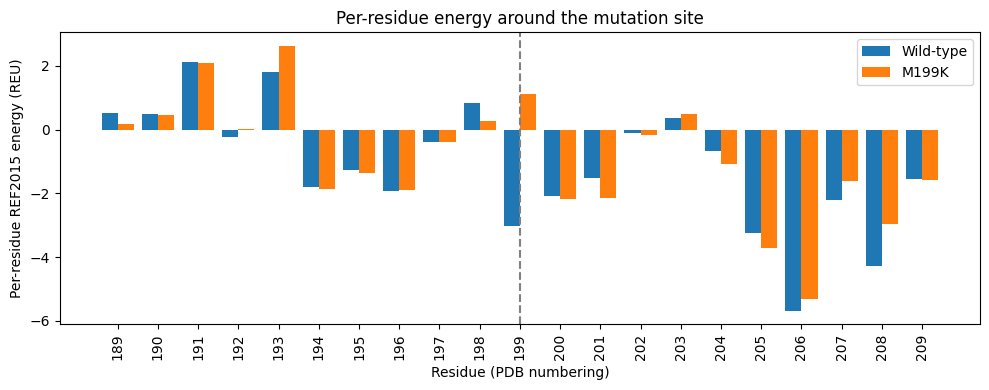

In [ ]:
# per-residue energy around the mutation site, wild-type vs mutant
mut_pose_final = mutate_and_relax(wt_pose, pose_199, "K")
wt_pose_final = mutate_and_relax(wt_pose, pose_199, wt_aa)

window = range(max(1, pose_199 - 10), min(wt_pose_final.total_residue(), pose_199 + 10) + 1)
res_E_wt = [wt_pose_final.energies().residue_total_energy(i) for i in window]
res_E_mut = [mut_pose_final.energies().residue_total_energy(i) for i in window]
pdb_numbers = [info.number(i) for i in window]

plt.figure(figsize=(10, 4))
x = np.arange(len(pdb_numbers))
plt.bar(x - 0.2, res_E_wt, width=0.4, label="Wild-type")
plt.bar(x + 0.2, res_E_mut, width=0.4, label="M199K")
plt.xticks(x, pdb_numbers, rotation=90)
plt.xlabel("Residue (PDB numbering)")
plt.ylabel("Per-residue REF2015 energy (REU)")
plt.title("Per-residue energy around the mutation site")
plt.axvline(x[pdb_numbers.index(199)], color="gray", linestyle="--")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/per_residue_energy.png", dpi=150)
plt.show()

## C. Molecular dynamics (OpenMM + AMBER force field)


In [ ]:
from pdbfixer import PDBFixer
from openmm.app import Modeller, PDBFile, ForceField, PME, HBonds, Simulation, DCDReporter, StateDataReporter
from openmm import LangevinMiddleIntegrator, Platform, unit
import sys

def prepare_system(pdb_path, out_prefix):
    fixer = PDBFixer(filename=pdb_path)
    fixer.findMissingResidues()
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()
    fixer.addMissingHydrogens(7.0)

    forcefield = ForceField("amber14-all.xml", "amber14/tip3pfb.xml")
    modeller = Modeller(fixer.topology, fixer.positions)
    modeller.addSolvent(forcefield, model="tip3p", padding=1.0 * unit.nanometers,
                         ionicStrength=0.15 * unit.molar)

    with open(f"{OUT_DIR}/{out_prefix}_solvated.pdb", "w") as f:
        PDBFile.writeFile(modeller.topology, modeller.positions, f)
    return forcefield, modeller

ff_wt, model_wt_md = prepare_system(WT_PATH, "wt")
ff_mut, model_mut_md = prepare_system(MUT_PATH, "mut")
print("Both structures solvated and ready for MD.")

Both structures solvated and ready for MD.


In [ ]:
PRODUCTION_STEPS = 50000   # 100 ps at 2 fs/step -- short limited GPU time.
EQUILIBRATION_STEPS = 5000

def run_md(forcefield, modeller, out_prefix):
    system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME,
                                      nonbondedCutoff=1.0 * unit.nanometers, constraints=HBonds)
    integrator = LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, 0.002 * unit.picoseconds)
    try:
        platform = Platform.getPlatformByName("CUDA")
    except Exception:
        platform = Platform.getPlatformByName("CPU")

    simulation = Simulation(modeller.topology, system, integrator, platform)
    simulation.context.setPositions(modeller.positions)

    print(f"[{out_prefix}] Minimizing...")
    simulation.minimizeEnergy()
    print(f"[{out_prefix}] Equilibrating...")
    simulation.context.setVelocitiesToTemperature(300 * unit.kelvin)
    simulation.step(EQUILIBRATION_STEPS)

    print(f"[{out_prefix}] Running production...")
    simulation.reporters.append(DCDReporter(f"{OUT_DIR}/{out_prefix}_traj.dcd", 500))
    simulation.reporters.append(StateDataReporter(sys.stdout, 5000, step=True, potentialEnergy=True, temperature=True))
    simulation.step(PRODUCTION_STEPS)

    with open(f"{OUT_DIR}/{out_prefix}_final.pdb", "w") as f:
        PDBFile.writeFile(simulation.topology, simulation.context.getState(getPositions=True).getPositions(), f)
    print(f"[{out_prefix}] Done.")

run_md(ff_wt, model_wt_md, "wt")
run_md(ff_mut, model_mut_md, "mut")

[wt] Minimizing...
[wt] Equilibrating...
[wt] Running production...
#"Step","Potential Energy (kJ/mole)","Temperature (K)"
10000,-616478.7937865856,300.5488739795214
15000,-618777.5904758184,300.1495037557155
20000,-619270.5048244891,298.40314436116137
25000,-619683.8035411466,300.1225361658752
30000,-618805.4256762232,300.62725068960964
35000,-618777.5396482113,297.74981691839366
40000,-618100.3241103889,299.0214634323672
45000,-618457.5796941422,299.7131766647684
50000,-618867.1598045868,301.7851537204974
55000,-618908.3924869037,299.41224220426636
[wt] Done.
[mut] Minimizing...
[mut] Equilibrating...
[mut] Running production...
#"Step","Potential Energy (kJ/mole)","Temperature (K)"
10000,-622864.4146027021,302.77632980491467
15000,-625208.5757696154,299.60174837394254
20000,-624585.2306636454,300.79365172191143
25000,-625501.3564368412,300.5591898083559
30000,-623632.6689133185,299.5422324900511
35000,-625406.4673662818,299.835743592096
40000,-624669.7781043096,298.8609195899533
450

In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import rms, align

# OpenMM/PDBFixer renumber residues from 1 when the solvated PDB is written.
# FIRST_RES is the first residue number in the original PDB (162), so we can map back.
FIRST_RES = min(r.id[1] for r in chain_wt if r.id[0] == " ")

def compute_rmsd_rmsf(solvated_pdb, traj_dcd):
    u = mda.Universe(solvated_pdb, traj_dcd)
    protein = u.select_atoms("protein and backbone")
    R = rms.RMSD(protein, protein, ref_frame=0).run()
    rmsd_series = R.results.rmsd[:, 2]

    align.AlignTraj(u, u, select="protein and backbone", in_memory=True).run()
    ca = u.select_atoms("protein and name CA")
    R_f = rms.RMSF(ca).run()
    # shift the renumbered residues back to the original PDB numbering (162-317)
    resids_pdb = ca.resids - ca.resids[0] + FIRST_RES
    return rmsd_series, resids_pdb, R_f.results.rmsf

rmsd_wt, resids_wt, rmsf_wt = compute_rmsd_rmsf(f"{OUT_DIR}/wt_solvated.pdb", f"{OUT_DIR}/wt_traj.dcd")
rmsd_mut, resids_mut, rmsf_mut = compute_rmsd_rmsf(f"{OUT_DIR}/mut_solvated.pdb", f"{OUT_DIR}/mut_traj.dcd")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(rmsd_wt, label="Wild-type")
axes[0].plot(rmsd_mut, label="M199K")
axes[0].set_xlabel("Frame"); axes[0].set_ylabel("Backbone RMSD (A)")
axes[0].set_title("RMSD over the simulation"); axes[0].legend()

axes[1].plot(resids_wt, rmsf_wt, label="Wild-type")
axes[1].plot(resids_mut, rmsf_mut, label="M199K")
axes[1].axvline(199, color="gray", linestyle="--", label="Residue 199")
axes[1].set_xlabel("Residue number"); axes[1].set_ylabel("RMSF (A)")
axes[1].set_title("Per-residue flexibility"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/rmsd_rmsf_comparison.png", dpi=150)
plt.show()

print("Mean RMSD -- wild-type: %.2f A, M199K: %.2f A" % (rmsd_wt.mean(), rmsd_mut.mean()))
idx_wt = list(resids_wt).index(199) if 199 in resids_wt else None
idx_mut = list(resids_mut).index(199) if 199 in resids_mut else None
if idx_wt is not None and idx_mut is not None:
    print("RMSF at residue 199 -- wild-type: %.2f A, M199K: %.2f A" % (rmsf_wt[idx_wt], rmsf_mut[idx_mut]))

## Summary

- **Structural comparison (A):** the distance table and view show how much the local geometry around position 199 shifts once lysine replaces methionine.
- **PyRosetta (B):** `ddG_fold` is your single number for whether M199K is predicted to destabilize RANKL's fold. Positive = destabilizing, which is what Qiu et al. found experimentally with differential scanning fluorimetry.
- **Molecular dynamics (C):** the RMSD plot shows whether the mutant drifts more over time (global stability), and the RMSF plot shows exactly where (local flexibility), ideally spiking near residue 199 if the mutation is destabilizing that region.

Limitations : N_REPEATS = 1  and PRODUCTION_STEP